# Mid term project: predict the count of total rental bikes

## Load the data

In [32]:
import io
import zipfile
import urllib.request
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np, pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

 

url = "https://archive.ics.uci.edu/static/public/265/physicochemical+properties+of+protein+tertiary+structure.zip"
z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
print(z.namelist())                     # should show CASP.csv
df = pd.read_csv(z.open("CASP.csv"))
print(df.shape)                         # expect (45730, 10)

['CASP.csv']
(45730, 10)


In [20]:
TARGET = "RMSD"
PREDICTORS = [f"F{i}" for i in range(1, 10)]
SEED = 42

## Split the data

In [36]:
df_rest, df_test = train_test_split(df, test_size=0.20, random_state=SEED)
# step 2: split the rest into train (75% of 80% = 60%) and calibration (25% of 80% = 20%)
df_train, df_cal = train_test_split(df_rest, test_size=0.25, random_state=SEED)
 
for name, d in [("train", df_train), ("calibration", df_cal), ("test", df_test)]:
    print(f"{name:12s} n = {len(d):6d}   mean RMSD = {d[TARGET].mean():.3f}")
 
# sanity check: the three sets are disjoint
assert not set(df_train.index) & set(df_cal.index)
assert not set(df_train.index) & set(df_test.index)
assert not set(df_cal.index) & set(df_test.index)
 
# save the indices so that every later script uses exactly the same split
pd.Series(df_train.index).to_csv("idx_train.csv", index=False)
pd.Series(df_cal.index).to_csv("idx_cal.csv", index=False)
pd.Series(df_test.index).to_csv("idx_test.csv", index=False)
 
X_train, y_train = df_train[FEATURES], df_train[TARGET]
X_cal,   y_cal   = df_cal[FEATURES],   df_cal[TARGET]
X_test,  y_test  = df_test[FEATURES],  df_test[TARGET]
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
 

train        n =  27438   mean RMSD = 7.779
calibration  n =   9146   mean RMSD = 7.672
test         n =   9146   mean RMSD = 7.734


## OLS

In [56]:
#First add the constant term to the predictors for the intercept in the regression model
X_train_c = sm.add_constant(X_train)
X_test_c  = sm.add_constant(X_test)
 
ols = sm.OLS(y_train, X_train_c).fit()
pred_ols_train = ols.predict(X_train_c)
pred_ols_test = ols.predict(X_test_c)
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                   RMSD   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.283
Method:                 Least Squares   F-statistic:                     1205.
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:01:03   Log-Likelihood:                -84038.
No. Observations:               27438   AIC:                         1.681e+05
Df Residuals:                   27428   BIC:                         1.682e+05
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.7286      0.754      8.923      0.0

## Few checks on the training set

### Is the data skewed?

            mean         sd        min      median         max   skew  \
RMSD        7.78       6.11       0.00        5.09       21.00   0.56   
F1       9879.11    4083.17    2392.05     8904.81    40034.90   1.12   
F2       3019.95    1474.59     411.31     2670.04    15312.00   1.22   
F3          0.30       0.06       0.09        0.30        0.58   0.23   
F4        103.52      55.65      10.69       87.88      369.32   1.24   
F5    1369396.28  567335.15  319490.22  1238191.19  5472011.41   1.08   
F6        145.80      70.47      32.87      126.32      598.41   1.15   
F7       3984.47    1872.92       0.00     3839.21   105476.80  18.70   
F8         69.92      56.16       0.00       54.00      350.00   1.68   
F9         34.51       6.00      15.31       35.29       55.07  -0.48   

      excess_kurtosis  
RMSD            -1.15  
F1               1.46  
F2               2.24  
F3               0.05  
F4               1.42  
F5               1.32  
F6               1.23  
F7  

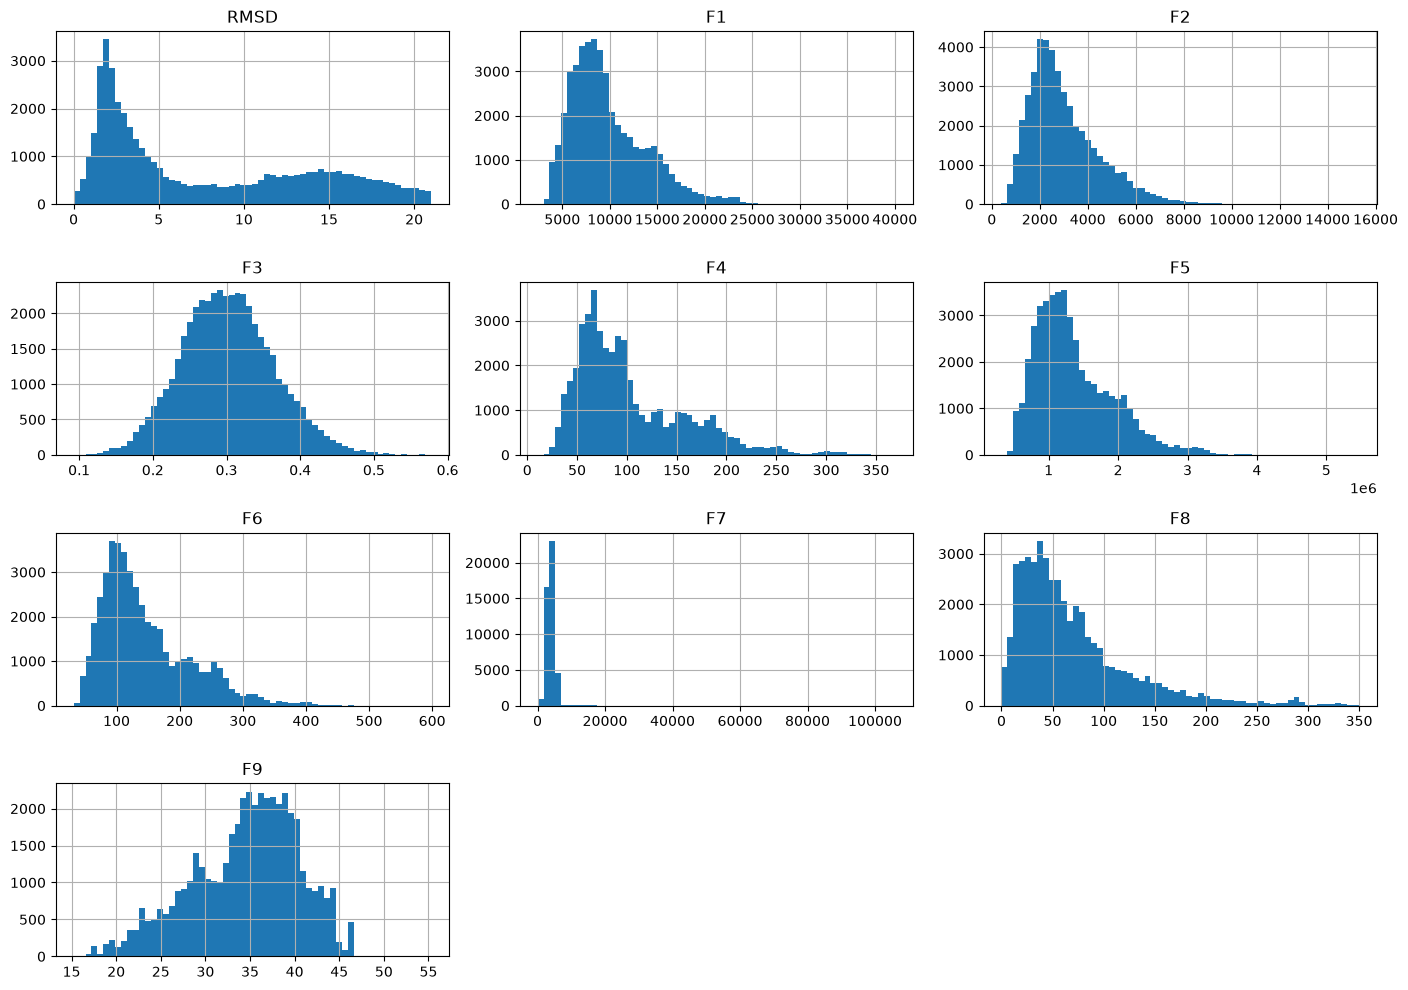

In [38]:

import matplotlib.pyplot as plt
from scipy import stats

# 1. Summary table
summary = pd.DataFrame({
    "mean": df_train.mean(), "sd": df_train.std(),
    "min": df_train.min(), "median": df_train.median(), "max": df_train.max(),
    "skew": df_train.skew(), "excess_kurtosis": df_train.kurt(),
})
print(summary.round(2))

# 2. Histograms
df.hist(bins=60, figsize=(14, 10))
plt.tight_layout(); plt.show()

### Is there substancial heteroskedasticity?

Breusch-Pagan LM = 1389.2, p-value = 1.68e-293


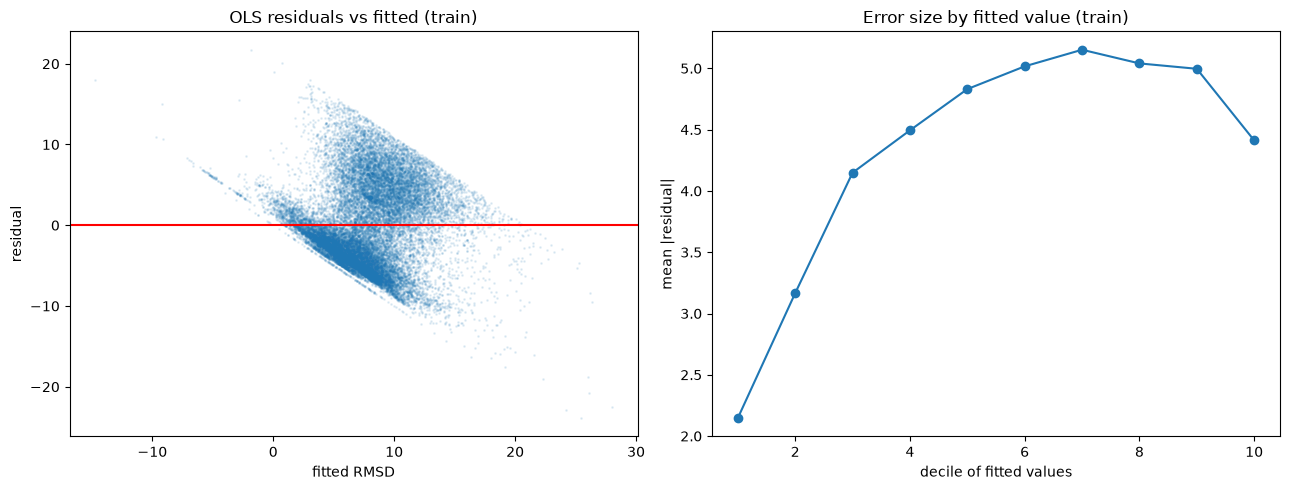

In [28]:
resid = ols.resid
fitted = ols.fittedvalues

lm, lm_p, f, f_p = het_breuschpagan(resid, X_train_c)
print(f"Breusch-Pagan LM = {lm:.1f}, p-value = {lm_p:.3g}")
#Rejected but bc n is large.
 
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(fitted, resid, s=1, alpha=.1)
ax[0].axhline(0, color="r")
ax[0].set(xlabel="fitted RMSD", ylabel="residual", title="OLS residuals vs fitted (train)")

# spread of residuals by decile of fitted values: shows heteroskedasticity clearly
bins = pd.qcut(fitted, 10)
spread = resid.abs().groupby(bins, observed=True).mean()
ax[1].plot(range(1, 11), spread.values, "o-")
ax[1].set(xlabel="decile of fitted values", ylabel="mean |residual|",
          title="Error size by fitted value (train)")
plt.tight_layout()
plt.savefig("ols_residuals.png", dpi=120)
plt.show()
 

### Colinearity

In [39]:
#variance inflation factor (VIF) measures how much each coefficient’s variance is inflated by 
# collinearity.
LABELS = {"F1": "total surface area",
          "F2": "non-polar exposed area",
          "F3": "fractional area of exposed non-polar residue",
          "F4": "fractional area of exposed non-polar part of residue",
          "F5": "molecular-mass-weighted exposed area",
          "F6": "average deviation from standard exposed area",
          "F7": "Euclidean distance",
          "F8": "secondary structure penalty",
          "F9": "spatial distribution constraints (N,K value)"}

Xc = sm.add_constant(X_train[FEATURES])      # VIF must be computed WITH the constant

# VIF_j = 1 / (1 - R2_j), where R2_j comes from regressing F_j on the other predictors
vif = pd.Series([variance_inflation_factor(Xc.values, i)
                 for i in range(1, Xc.shape[1])],   # i = 0 is the constant: skip it
                index=FEATURES)

def reading(v):
    if v < 5:    return "fine"
    if v < 10:   return "moderate"
    if v < 20:   return "strong"
    if v < 100:  return "severe"
    return "almost entirely redundant"

vif_table = pd.DataFrame({
    "description": pd.Series(LABELS),
    "VIF": vif,
    "R2_j": 1 - 1 / vif,                      # share of F_j explained by the others
    "SE_inflation": np.sqrt(vif),             # factor by which the SE is inflated
    "intepretation": vif.apply(reading),
}).sort_values("VIF", ascending=False)

print(vif_table.round({"VIF": 1, "R2_j": 3, "SE_inflation": 1}).to_string())

                                             description    VIF   R2_j  SE_inflation              intepretation
F1                                    total surface area  427.6  0.998          20.7  almost entirely redundant
F5                  molecular-mass-weighted exposed area  311.3  0.997          17.6  almost entirely redundant
F2                                non-polar exposed area   46.7  0.979           6.8                     severe
F6          average deviation from standard exposed area   25.8  0.961           5.1                     severe
F4  fractional area of exposed non-polar part of residue   14.2  0.929           3.8                     strong
F3          fractional area of exposed non-polar residue    7.5  0.867           2.7                   moderate
F9          spatial distribution constraints (N,K value)    6.1  0.835           2.5                   moderate
F8                           secondary structure penalty    1.9  0.476           1.4                    

## Random forest

### Initialize a baseline random forest regressor with default hyperparameters

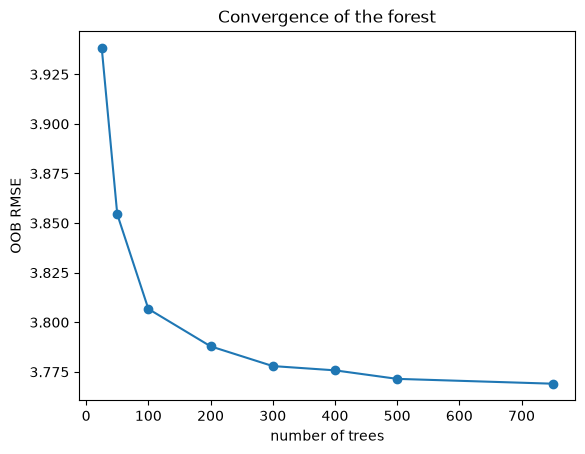

In [ ]:
from sklearn.model_selection import KFold, GridSearchCV

#Hastie, T., Tibshirani, R. & Friedman, J. (2009):
# recommend m (number of predictors to be randomly selected)of ⌊p/3⌋ , so 9.
# minimum node size of 5

#for the number of trees: no binding constraint. Each tree is a noisy estimate, and the forest averages B of them. As B grows, the average stabilizes and converges to its limit (Breinman, 2001), so more trees are better. 
# 1000 is a good number.

#max depth as None: random forests don’t need pruning: averaging many deep trees reduces the variance.

#bootstrap, oob_score = true. We want baggins and in the end the oob score 
# which has to be compared with 

#First, check that 500 is not binding, by plotting OOB RMSE as a function of the number of trees.
###warm_start=True to not start over every time, just add trees to the existing ones.
best_params = {"max_features": 3, "min_samples_leaf": 5}   # <- replace with YOUR grid.best_params_

rf_check = RandomForestRegressor(warm_start=True, oob_score=True, n_jobs=-1,
                                 random_state=SEED, **best_params)
n_trees = [25, 50, 100, 200, 300, 400, 500, 750]
oob_rmse = []
for B in n_trees:
    rf_check.set_params(n_estimators=B)
    rf_check.fit(X_train, y_train)            # adds trees to the existing ones
    oob_rmse.append(np.sqrt(mean_squared_error(y_train, rf_check.oob_prediction_)))

plt.plot(n_trees, oob_rmse, "o-")
plt.xlabel("number of trees"); plt.ylabel("OOB RMSE"); plt.title("Convergence of the forest")
plt.show()
#500 is indeed enough, as the OOB RMSE has stabilized by then.

In [44]:
rf0 = RandomForestRegressor(
    n_estimators=500,       # number of trees: more is never worse, only slower
    max_features=3,         # variables tried at each split: sqrt(9) = 9/3 = 3
    min_samples_leaf=5,     # minimum obs. per leaf 
    max_depth=None,         # trees grown fully, depth controlled by min_samples_leaf
    bootstrap=True,         # each tree on a bootstrap sample (= bagging)
    oob_score=True,         # out-of-bag R2: free estimate of out-of-sample error
    n_jobs=-1,              # use all CPU cores
    random_state=SEED,
)
rf0.fit(X_train, y_train)
oob_rmse = np.sqrt(mean_squared_error(y_train, rf0.oob_prediction_))
print(f"baseline RF: OOB R2 = {rf0.oob_score_:.3f}, OOB RMSE = {oob_rmse:.3f} ")

baseline RF: OOB R2 = 0.619, OOB RMSE = 3.771 


In [ ]:
### Fine tune hyperparameters using grid search and cross-validation.

In [47]:
#Here: n_estimators = 300 as, as seen before, going beyond 300 trees does not improve the OOB RMSE so much, and 500 would cost too much time.
param_grid = {
    "max_features":     [2, 3, 5, 9],        # 9 = all variables = plain bagging
    "min_samples_leaf": [1, 5, 10, 20],
}
grid = GridSearchCV(
    RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED),
    param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,               # parallelism already inside the forest
    verbose=1,
)
grid.fit(X_train, y_train)
print("best parameters:", grid.best_params_)
print(f"best CV RMSE: {-grid.best_score_:.3f}")
 
# table of all CV results (useful for an appendix)
cv_res = pd.DataFrame(grid.cv_results_)[
    ["param_max_features", "param_min_samples_leaf",
     "mean_test_score", "std_test_score"]]
cv_res["CV_RMSE"] = -cv_res["mean_test_score"]
print(cv_res.pivot(index="param_min_samples_leaf",
                   columns="param_max_features", values="CV_RMSE").round(3))
 

Fitting 5 folds for each of 16 candidates, totalling 80 fits
best parameters: {'max_features': 5, 'min_samples_leaf': 1}
best CV RMSE: 3.659
param_max_features          2      3      5      9
param_min_samples_leaf                            
1                       3.712  3.678  3.659  3.683
5                       3.906  3.848  3.804  3.805
10                      4.055  3.997  3.949  3.943
20                      4.237  4.178  4.128  4.126


### Final forest

In [57]:
rf = RandomForestRegressor(n_estimators=500, oob_score=True, n_jobs=-1,
                           random_state=SEED, **grid.best_params_)
rf.fit(X_train, y_train)
 
def metrics(y, yhat):
    return {"RMSE": np.sqrt(mean_squared_error(y, yhat)),
            "MAE":  mean_absolute_error(y, yhat),
            "R2":   r2_score(y, yhat)}
 
results = pd.DataFrame({
    "train (in-sample)": metrics(y_train, rf.predict(X_train)),   # optimistic, as deep trees memorize their training data, and the averaging only acts on new data.
    "train (OOB)":       metrics(y_train, rf.oob_prediction_),    # honest
    "test":              metrics(y_test,  rf.predict(X_test)),
}).T
print(results.round(3))

pred_rf_oob    = rf.oob_prediction_
pred_rf_test = rf.predict(X_test)

 

                    RMSE    MAE     R2
train (in-sample)  1.318  0.913  0.953
train (OOB)        3.572  2.481  0.659
test               3.566  2.509  0.662


### Impurity based feature performance

In [ ]:
### Impurity based feature importance (MDI)
# It is based on the total reduction of the criterion (MSE) brought by that feature. 
# It is biased towards continuous and high-cardinality categorical variables, 
# and it is not reliable when predictors are correlated.
# i still put it just in case, but we have to mention its limits.

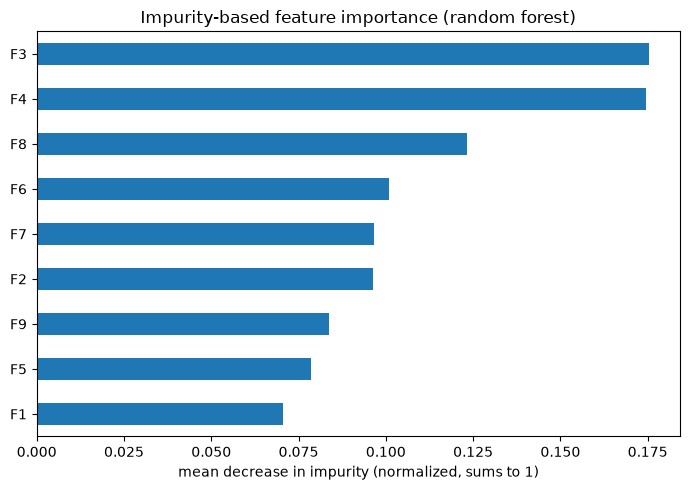

In [51]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax)
ax.set(title="Impurity-based feature importance (random forest)",
       xlabel="mean decrease in impurity (normalized, sums to 1)")
plt.tight_layout()
plt.savefig("rf_feature_importance.png", dpi=120)
plt.show()

### Check for heteroskedasticity in the residuals of the random forest model 

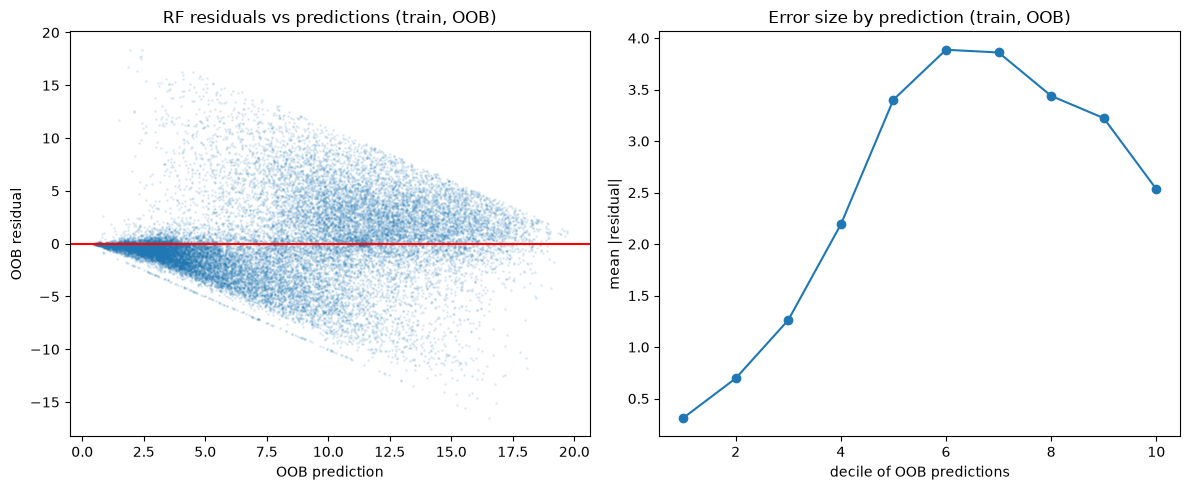

In [52]:
resid_oob = y_train - rf.oob_prediction_
resid_oob = y_train - rf.oob_prediction_
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
 
ax[0].scatter(rf.oob_prediction_, resid_oob, s=1, alpha=.1)
ax[0].axhline(0, color="r")
ax[0].set(xlabel="OOB prediction", ylabel="OOB residual",
          title="RF residuals vs predictions (train, OOB)")
 
bins = pd.qcut(rf.oob_prediction_, 10)
spread = resid_oob.abs().groupby(bins, observed=True).mean()
ax[1].plot(range(1, 11), spread.values, "o-")
ax[1].set(xlabel="decile of OOB predictions", ylabel="mean |residual|",
          title="Error size by prediction (train, OOB)")
 
plt.tight_layout()
plt.savefig("rf_diagnostics.png", dpi=120)
plt.show()
 

## Comparison OLS - RF

In [58]:
pred_base  = np.full(len(y_test),  y_train.mean())   # même valeur pour chaque obs. du test, juste la moyenne
base_train = np.full(len(y_train), y_train.mean())  # same


rows = {
    "Baseline (mean)": (metrics(y_train, base_train),     metrics(y_test, pred_base)),
    "OLS":             (metrics(y_train, pred_ols_train), metrics(y_test, pred_ols_test)),
    "Random forest":   (metrics(y_train, pred_rf_oob),    metrics(y_test, pred_rf_test)),
}
table1 = pd.DataFrame({
    m: {f"{k} {s}": v for s, d in zip(["train", "test"], (tr, te)) for k, v in d.items()}
    for m, (tr, te) in rows.items()
}).T[["RMSE train", "RMSE test", "MAE train", "MAE test", "R2 train", "R2 test"]]

print(table1.round(3))
table1.round(3).to_csv("table1_performance.csv")

                 RMSE train  RMSE test  MAE train  MAE test  R2 train  R2 test
Baseline (mean)       6.114      6.135      5.490     5.501     0.000   -0.000
OLS                   5.175      5.241      4.340     4.388     0.283    0.270
Random forest         3.572      3.566      2.481     2.509     0.659    0.662
